# 4장. 전처리

In [1]:
# [준비 셀] 모든 노트북의 첫 코드 셀입니다. 항상 먼저 실행하세요.
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parents[1]          # docs/manual → 프로젝트 루트
assert (ROOT / "src/bearing_kd").exists(), "docs/manual 폴더에서 노트북을 열어야 합니다"
CODE = ROOT / "docs/manual/code"                 # 챕터별 완성 스크립트 위치
sys.path.insert(0, str(CODE))                    # 스크립트의 함수를 import 해서 쓰기 위해
print("프로젝트 루트 확인 완료:", ROOT.name)

프로젝트 루트 확인 완료: vib-onnx


원본 신호는 그대로 모델에 넣기엔 너무 길고 촘촘합니다. 이 장에서는 64 kHz, 4초 신호를 **4 kHz, 1초짜리 조각(윈도우)** 여러 개로 바꿉니다.

```text
.mat → vibration_1 (64 kHz, 256,001개)
     → ① 1 kHz 저역통과 필터
     → ② 4 kHz로 리샘플링 (16,000개)
     → ③ 1초(4,000개) 윈도우, 0.5초(2,000개)씩 이동 → 윈도우 7개
```

이 규칙은 학습, 평가, 라즈베리파이 추론에서 **항상 똑같이** 써야 합니다. 그래서 이 프로젝트는 이 규칙을 "전처리 계약"이라고 부릅니다.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import ch04_preprocess as ch04

for k in ["RAW_FS", "SAMPLE_RATE", "CUTOFF_HZ", "FILTER_ORDER", "WINDOW_SIZE", "STRIDE"]:
    print(f"{k:13s} = {getattr(ch04, k):,}")

RAW_FS        = 64,000
SAMPLE_RATE   = 4,000
CUTOFF_HZ     = 1,000
FILTER_ORDER  = 8
WINDOW_SIZE   = 4,000
STRIDE        = 2,000


## 4.1 샘플링 레이트: 1초에 몇 번 찍나

64 kHz는 신호의 주파수가 아니라 **1초에 값을 64,000번 기록했다**는 뜻입니다. 파형을 알아보려면 한 번 흔들릴 때 최소 2번은 찍어야 합니다(위에서 한 번, 아래에서 한 번). 그래서:

> **샘플링 레이트가 `fs`이면 담을 수 있는 가장 빠른 진동은 `fs / 2`** (나이퀴스트 주파수)

| 샘플링 레이트 | 담을 수 있는 최대 주파수 |
|---|---|
| 64 kHz (원본) | 32 kHz |
| 4 kHz (우리가 쓰는 값) | **2 kHz** |

## 4.2 너무 빠른 진동은 가짜로 둔갑한다 (에일리어싱)

7,000 Hz 진동을 4 kHz로 찍으면, 찍힌 점들을 이은 모양이 **1,000 Hz 진동처럼** 보입니다. 원래 없던 신호가 생기는 것입니다.

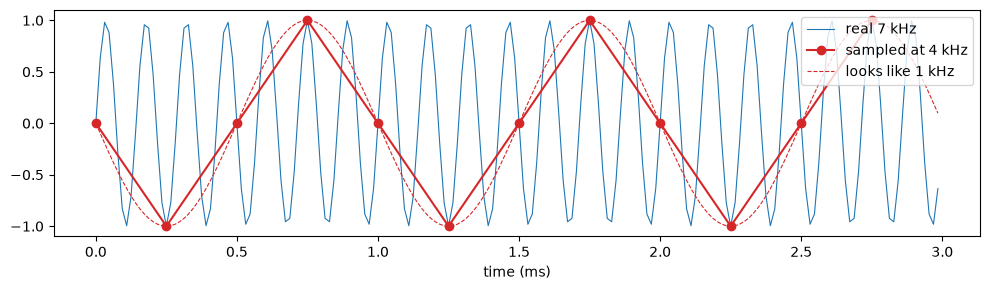

In [3]:
t_fine = np.arange(0, 0.003, 1 / 64000)          # 64 kHz로 3 ms
t_coarse = np.arange(0, 0.003, 1 / 4000)         # 4 kHz로 3 ms
f = 7000
plt.figure(figsize=(10, 3))
plt.plot(t_fine * 1000, np.sin(2 * np.pi * f * t_fine), lw=0.8, label="real 7 kHz")
plt.plot(t_coarse * 1000, np.sin(2 * np.pi * f * t_coarse), "o-", color="C3", label="sampled at 4 kHz")
plt.plot(t_fine * 1000, np.sin(2 * np.pi * -1000 * t_fine), "--", color="C3", lw=0.8, label="looks like 1 kHz")
plt.xlabel("time (ms)"); plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

그래서 샘플링 레이트를 낮추기 **전에** 담을 수 없는 빠른 진동을 먼저 지워야 합니다. 이것이 **저역통과 필터(low-pass filter)**입니다. 이 프로젝트는 여유를 두고 1 kHz 위를 지웁니다.

## 4.3 Butterworth 저역통과 필터

- **Butterworth**: 통과 대역이 평평한(신호를 왜곡하지 않는) 대표적인 필터
- **차수 8**: 숫자가 클수록 차단 주파수 근처에서 더 가파르게 깎습니다
- **sos 형식**: 차수가 높은 필터를 2차 필터 여러 개로 나눠 계산해 숫자 오차를 줄이는 방식

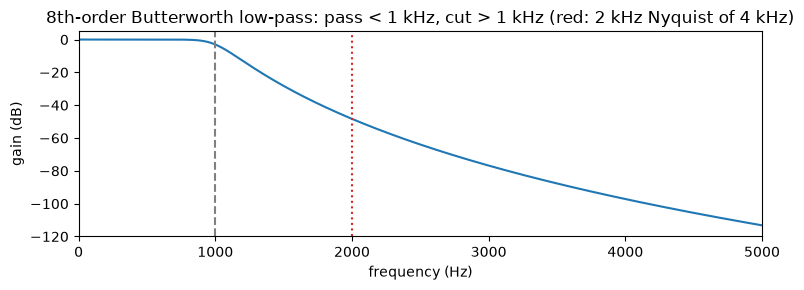

sos 모양: (4, 6) ← 2차 필터 4개


In [4]:
from scipy.signal import butter, sosfreqz

sos = butter(ch04.FILTER_ORDER, ch04.CUTOFF_HZ / (ch04.RAW_FS / 2), btype="lowpass", output="sos")
w, h = sosfreqz(sos, worN=8192, fs=ch04.RAW_FS)
plt.figure(figsize=(8, 3))
plt.plot(w, 20 * np.log10(np.maximum(np.abs(h), 1e-10)))
plt.axvline(1000, color="gray", ls="--"); plt.axvline(2000, color="C3", ls=":")
plt.xlim(0, 5000); plt.ylim(-120, 5)
plt.xlabel("frequency (Hz)"); plt.ylabel("gain (dB)")
plt.title("8th-order Butterworth low-pass: pass < 1 kHz, cut > 1 kHz (red: 2 kHz Nyquist of 4 kHz)")
plt.tight_layout(); plt.show()
print("sos 모양:", sos.shape, "← 2차 필터 4개")

## 4.4 왜 `sosfiltfilt`(양방향)를 쓰나

일반 필터(`sosfilt`)는 신호를 조금 **늦게** 만듭니다(위상 지연). `sosfiltfilt`는 앞으로 한 번, 뒤로 한 번 걸어서 지연을 없앱니다. 대신 **녹음이 끝나야** 쓸 수 있어서, 실시간 스트리밍에는 다른 방식이 필요합니다(15장).

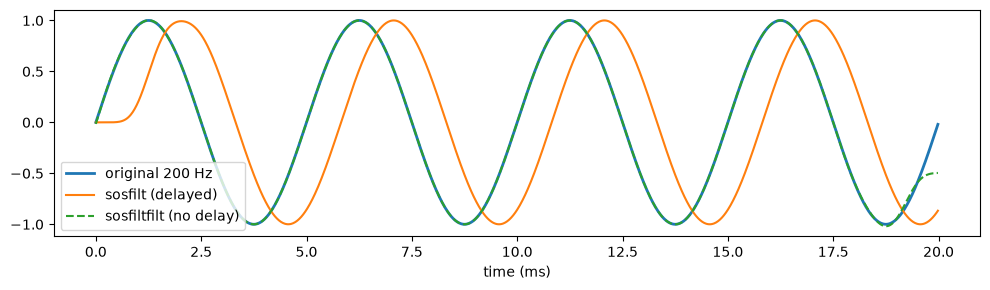

In [5]:
from scipy.signal import sosfilt, sosfiltfilt

t = np.arange(0, 0.02, 1 / 64000)
sig = np.sin(2 * np.pi * 200 * t)            # 200 Hz: 필터를 통과해야 하는 신호
plt.figure(figsize=(10, 3))
plt.plot(t * 1000, sig, lw=2, label="original 200 Hz")
plt.plot(t * 1000, sosfilt(sos, sig), label="sosfilt (delayed)")
plt.plot(t * 1000, sosfiltfilt(sos, sig), "--", label="sosfiltfilt (no delay)")
plt.xlabel("time (ms)"); plt.legend(); plt.tight_layout(); plt.show()

## 4.5 리샘플링: 64 kHz → 4 kHz

64,000 ÷ 4,000 = 16이므로 16개 중 1개만 남깁니다. `resample_poly(x, up=1, down=16)`는 단순히 건너뛰는 대신, 추가 보호 필터를 거쳐 안전하게 줄입니다.

실제 파일에 ①②를 적용해 봅니다.

원본  256,001개 (64 kHz, 4.00초)
변환  16,001개 (4 kHz, 4.00초)


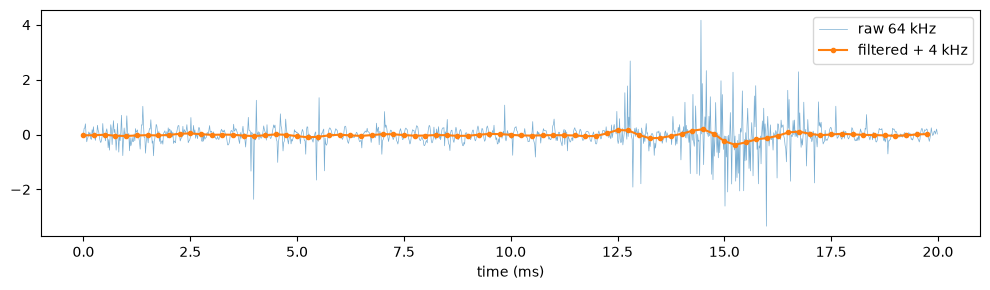

In [6]:
RAW = ROOT / "data/raw/paderborn"
raw = ch04.extract_vibration(RAW / "K001/N15_M07_F10_K001_1.mat")
down = ch04.preprocess_signal(raw)
print(f"원본  {raw.size:,}개 (64 kHz, {raw.size / 64000:.2f}초)")
print(f"변환  {down.size:,}개 (4 kHz, {down.size / 4000:.2f}초)")

fig, ax = plt.subplots(figsize=(10, 3))
n_raw = int(0.02 * 64000)
ax.plot(np.arange(n_raw) / 64000 * 1000, raw[:n_raw], lw=0.5, alpha=0.6, label="raw 64 kHz")
ax.plot(np.arange(n_raw // 16) / 4000 * 1000, down[:n_raw // 16], "o-", ms=3, label="filtered + 4 kHz")
ax.set_xlabel("time (ms)"); ax.legend(); plt.tight_layout(); plt.show()

빠른 떨림이 사라지고 느린 성분만 남았습니다.

### 4 kHz를 고른 이유와 대가

MOMENT 모델(7장)은 **한 번에 512개 샘플**만 받습니다. 그래서 샘플링 레이트가 "모델이 한 번에 보는 시간"과 "볼 수 있는 주파수"를 함께 정합니다.

| 샘플링 | 512개 = | 볼 수 있는 대역 | 1초 윈도우당 모델 실행 횟수 |
|---|---|---|---|
| 64 kHz | 8 ms | 0–32 kHz | 125번 |
| 16 kHz | 32 ms | 0–8 kHz | 32번 |
| **4 kHz** | **128 ms** | **0–2 kHz** | **8번** |

라즈베리파이에서 실시간으로 돌리려면 모델 실행 횟수가 적어야 해서 4 kHz를 골랐습니다. 대가로 **1 kHz 위의 고주파 정보는 모두 버립니다.** 이 데이터에서는 고장 정보가 2–10 kHz에도 많이 있어서, 이것이 12장에서 볼 성능 한계의 원인 중 하나로 추정됩니다.

## 4.6 윈도우로 자르기

16,000개 신호를 4,000개(1초)씩, 2,000개(0.5초)씩 밀면서 자릅니다.

```text
시작 위치:     0   2000  4000  6000  8000  10000  12000
윈도우:      [0────4000)
                 [2000──6000)
                       ...
                                          [12000───16000)
→ (16000 - 4000) / 2000 + 1 = 7개
```

윈도우끼리 절반씩 겹칩니다. 데이터를 더 많이 만들 수 있지만, **같은 파일의 윈도우들은 서로 비슷하다**는 뜻이기도 합니다(5장에서 중요).

In [7]:
demo = np.arange(16000, dtype=np.float32)
w = ch04.make_windows(demo)
print("윈도우 모양:", w.shape)
print("각 윈도우 시작값:", w[:, 0].astype(int).tolist())
print("1번 윈도우 뒤쪽 절반 == 2번 윈도우 앞쪽 절반?", np.array_equal(w[0, 2000:], w[1, :2000]))

windows = ch04.make_windows(down)
print("\n실제 파일:", windows.shape, windows.dtype)

윈도우 모양: (7, 4000)
각 윈도우 시작값: [0, 2000, 4000, 6000, 8000, 10000, 12000]
1번 윈도우 뒤쪽 절반 == 2번 윈도우 앞쪽 절반? True

실제 파일: (7, 4000) float32


## 4.7 저장 형식

파일마다 두 개의 `.npy`(NumPy 배열 파일)를 만듭니다.

```text
outputs/manual/processed/
├─ preprocessing.json                         ← 어떤 규칙으로 만들었는지 기록
├─ K001/
│  ├─ N15_M07_F10_K001_1_windows.npy          ← [7, 4000] float32
│  └─ N15_M07_F10_K001_1_labels.npy           ← [7] int64, 전부 0
└─ KA04/ ...
```

`preprocessing.json`을 남기는 이유: 나중에 필터 차수 같은 규칙을 바꾸면, 옛날 데이터와 새 데이터가 섞이는 사고를 막을 수 있습니다. 이 프로젝트의 옛날 KB24 데이터는 실제로 6차 필터로 만들어져 있었습니다.

## 4.8 맛보기 전처리 실행

베어링 4개(정상 K001·K002, 고장 KA03·KA04) × 파일 8개만 처리합니다. 운전 조건 4가지가 고르게 들어가도록 골랐습니다.

In [8]:
%run code/ch04_preprocess.py --overwrite

K001 (라벨 0): 파일 8개 → 윈도우 56개


K002 (라벨 0): 파일 8개 → 윈도우 57개


KA03 (라벨 1): 파일 8개 → 윈도우 56개


KA04 (라벨 1): 파일 8개 → 윈도우 56개

합계: 파일 32개, 윈도우 225개 → outputs/manual/processed


In [9]:
import json
PROC = ROOT / "outputs/manual/processed"
print(json.dumps(json.loads((PROC / "preprocessing.json").read_text()), indent=2, ensure_ascii=False))
f = sorted((PROC / "KA04").glob("*_windows.npy"))[0]
print(f.name, np.load(f).shape, "/ labels", np.load(str(f).replace("_windows", "_labels")).tolist())

{
  "raw_sample_rate": 64000,
  "sample_rate": 4000,
  "cutoff_hz": 1000,
  "filter_order": 8,
  "filter": "butter-sosfiltfilt",
  "window_size": 4000,
  "stride": 2000,
  "files": 32,
  "windows": 225
}
N09_M07_F10_KA04_10_windows.npy (7, 4000) / labels [1, 1, 1, 1, 1, 1, 1]


## 4.9 실제 프로젝트 전처리와 같은지 확인

매뉴얼 코드가 `src/bearing_kd/preprocessing.py`와 같은 결과를 내는지 비교합니다. 차이가 0이면 완전히 같습니다.

In [10]:
sys.path.insert(0, str(ROOT / "src"))
from bearing_kd.preprocessing import preprocess_file as project_preprocess

diff = 0.0
for f in sorted(PROC.rglob("*_windows.npy"))[:6]:
    raw_path = ROOT / "data/raw/paderborn" / f.parent.name / f.name.replace("_windows.npy", ".mat")
    diff = max(diff, float(np.abs(np.load(f) - project_preprocess(raw_path)).max()))
print("최대 차이:", diff)

최대 차이: 0.0


실제 프로젝트에서는 같은 일을 명령 한 줄로 합니다.
```bash
bearing-kd preprocess --bearings K001 K002 K003 K004 KA03 KA04 KI03 KB24 KB27 --output-dir data/processed/windows_v3
```

## 4장 완성 코드: `code/ch04_preprocess.py`

In [11]:
from IPython.display import Code
Code(filename=str(CODE / "ch04_preprocess.py"), language="python")

"""4장 완성 코드: 원본 64 kHz 진동을 모델 입력용 1초 윈도우로 전처리한다.

처리 순서 (src/bearing_kd/preprocessing.py와 같은 규칙):
    .mat → vibration_1 꺼내기 → 1 kHz 저역통과(Butterworth 8차, 양방향) → 4 kHz로 리샘플링
         → 4000샘플(1초) 윈도우, 2000샘플씩 이동 → *_windows.npy, *_labels.npy, preprocessing.json 저장

실행 (프로젝트 루트에서):
    # 맛보기: 베어링 4개 × 파일 8개 (수십 초)
    python docs/manual/code/ch04_preprocess.py
    # 전체: 파일 수 제한 없이
    python docs/manual/code/ch04_preprocess.py --bearings K001 K002 K003 K004 KA03 KA04 KI03 KB24 KB27 \
        --max-files 0 --output-dir outputs/manual/processed_full
"""

import argparse
import json
import re
import shutil
from pathlib import Path

import numpy as np
from scipy.io import loadmat
from scipy.signal import butter, resample_poly, sosfiltfilt

ROOT = Path(__file__).resolve().parents[3]

# ── 전처리 규칙(계약). 학습·추론·라즈베리파이 모두 이 값을 똑같이 써야 한다. ──
RAW_FS = 64_000       # 원본 샘플링 레이트
SAMPLE_RATE = 4_000   # 낮춘 샘플링 레이트 (라즈베리파이 속도 때문에 선택)
CUTOFF_HZ = 1_000     # 저역통과 차단 주파수 (4 kHz의 절반 2 kHz보다 충분히 낮게)
FILTER_ORDER = 8      # 필터 차수: 클수록 차단이 가파르다
WINDOW_SIZE = 4_000   # 1초 = 4000 샘플
STRIDE = 2_000        # 0.5초씩 이동 → 윈도우끼리 절반 겹침


def bearing_label(code):
    if re.fullmatch(r"K\d{3}", code):
        return 0
    if re.fullmatch(r"K[ABI]\d{2}", code):
        return 1
    raise ValueError(f"알 수 없는 베어링 코드: {code}")


def extract_vibration(path):
    path = Path(path)
    record = loadmat(path, squeeze_me=True, struct_as_record=False)[path.stem]
    for item in np.atleast_1d(record.Y):
        if str(item.Name) == "vibration_1":
            signal = np.asarray(item.Data, dtype=np.float32).reshape(-1)
            if signal.size == 0 or not np.isfinite(signal).all():
                raise ValueError(f"비어 있거나 NaN/무한대가 있는 신호: {path}")
            return signal
    raise ValueError(f"vibration_1 없음: {path}")


def preprocess_signal(signal):
    """64 kHz 신호 → 1 kHz 저역통과 → 4 kHz."""
    signal = np.asarray(signal, dtype=np.float32)
    sos = butter(FILTER_ORDER, CUTOFF_HZ / (RAW_FS / 2), btype="lowpass", output="sos")
    filtered = sosfiltfilt(sos, signal).astype(np.float32)  # 앞뒤로 두 번 → 위상(시간) 밀림 없음
    return resample_poly(filtered, up=1, down=RAW_FS // SAMPLE_RATE).astype(np.float32)  # 16개 중 1개


def make_windows(signal):
    """긴 신호를 4000샘플짜리 조각으로, 2000샘플씩 밀면서 자른다."""
    starts = range(0, len(signal) - WINDOW_SIZE + 1, STRIDE)
    return np.stack([signal[s:s + WINDOW_SIZE] for s in starts])


def preprocess_file(path):
    return make_windows(preprocess_signal(extract_vibration(path)))


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--raw-dir", default="data/raw/paderborn")
    parser.add_argument("--output-dir", default="outputs/manual/processed")
    parser.add_argument("--bearings", nargs="+", default=["K001", "K002", "KA03", "KA04"])
    parser.add_argument("--max-files", type=int, default=8, help="베어링당 파일 수 (0이면 전부)")
    parser.add_argument("--overwrite", action="store_true", help="출력 폴더가 있으면 지우고 다시 만든다")
    args = parser.parse_args()

    raw_dir, out_dir = ROOT / args.raw_dir, ROOT / args.output_dir
    if out_dir.exists() and any(out_dir.iterdir()):
        if not args.overwrite:
            raise SystemExit(f"{out_dir.relative_to(ROOT)} 가 비어 있지 않습니다. --overwrite 를 쓰거나 다른 경로를 주세요.")
        shutil.rmtree(out_dir)

    total_files = total_windows = 0
    for code in args.bearings:
        label = bearing_label(code)
        paths = sorted((raw_dir / code).glob("*.mat"))
        if args.max_files:
            # 운전 조건 4가지가 고르게 들어가도록 조건별로 번갈아 고른다
            by_condition = {}
            for p in paths:
                by_condition.setdefault(p.name[:11], []).append(p)
            paths = [p for group in zip(*by_condition.values()) for p in group][:args.max_files]
        if not paths:
            raise SystemExit(f"{code}: .mat 파일이 없습니다 (3장의 압축 풀기 참고)")
        (out_dir / code).mkdir(parents=True, exist_ok=True)
        count = 0
        for path in paths:
            windows = preprocess_file(path)
            np.sav